In [54]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080322
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp02
[学号] 20244080322
[机器指纹] b5a9a9b08d044ae2
[RUN_ID] 20244080322-b5a9a9b08d044ae2


## 1. wigner_density(x)：Wigner半圆密度函数
实现半圆定律密度函数，兼容标量与numpy数组


In [55]:
import hashlib
import os
import platform
import uuid
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
def wigner_density(x):
    x = np.asarray(x)
    res = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    res[mask] = 1/(2*np.pi) * np.sqrt(4 - x[mask]**2)
    if res.ndim == 0:
        return float(res)
    return res

# =====验证代码=====
print("wigner_density(-2):", wigner_density(-2))
print("wigner_density(0):", wigner_density(0))
print("wigner_density(2):", wigner_density(2))
print("wigner_density(3):", wigner_density(3))
arr_test = np.array([-1,0,1,2.5])
print("数组输入测试", arr_test, "输出：", wigner_density(arr_test))


wigner_density(-2): 0.0
wigner_density(0): 0.3183098861837907
wigner_density(2): 0.0
wigner_density(3): 0.0
数组输入测试 [-1.   0.   1.   2.5] 输出： [0.27566445 0.31830989 0.27566445 0.        ]


## 2. generate_wigner(n)：生成n阶Wigner对称随机矩阵
> 验证：输出矩阵shape，验证矩阵对称；测试非法n（负数、浮点数）触发异常



In [56]:
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n必须是正整数")
    mat = np.random.normal(loc=0, scale=np.sqrt(1/n), size=(n,n))
    mat = np.triu(mat)
    mat = mat + mat.T - np.diag(np.diag(mat))
    return mat

# =====验证代码=====
mat_test = generate_wigner(5)
print("矩阵shape:", mat_test.shape)
print("是否对称：", np.allclose(mat_test, mat_test.T))

try:
    generate_wigner(-3)
except ValueError as e:
    print("非法n=-3捕获异常：", e)
try:
    generate_wigner(2.5)
except ValueError as e:
    print("非法n=2.5捕获异常：", e)


矩阵shape: (5, 5)
是否对称： True
非法n=-3捕获异常： n必须是正整数
非法n=2.5捕获异常： n必须是正整数


## 3. get_spectrum(matrix)：获取矩阵全部特征值，非递减排序
> 验证：输出特征值数组，检查是否升序排列


In [57]:
def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals.sort()
    return eigvals

# =====验证代码=====
eig = get_spectrum(mat_test)
print("特征值：", eig)
print("是否非递减：", np.all(np.diff(eig)>=0))


特征值： [-1.47668368 -0.39937562  0.09162654  0.43861937  1.72960389]
是否非递减： True


## 4. 绘制4个子图 n=100,200,500,1000，直方图叠加半圆密度曲线
> 观察结论：n大约500时半圆密度已经可以较好拟合特征值分布；n=1000拟合效果更好


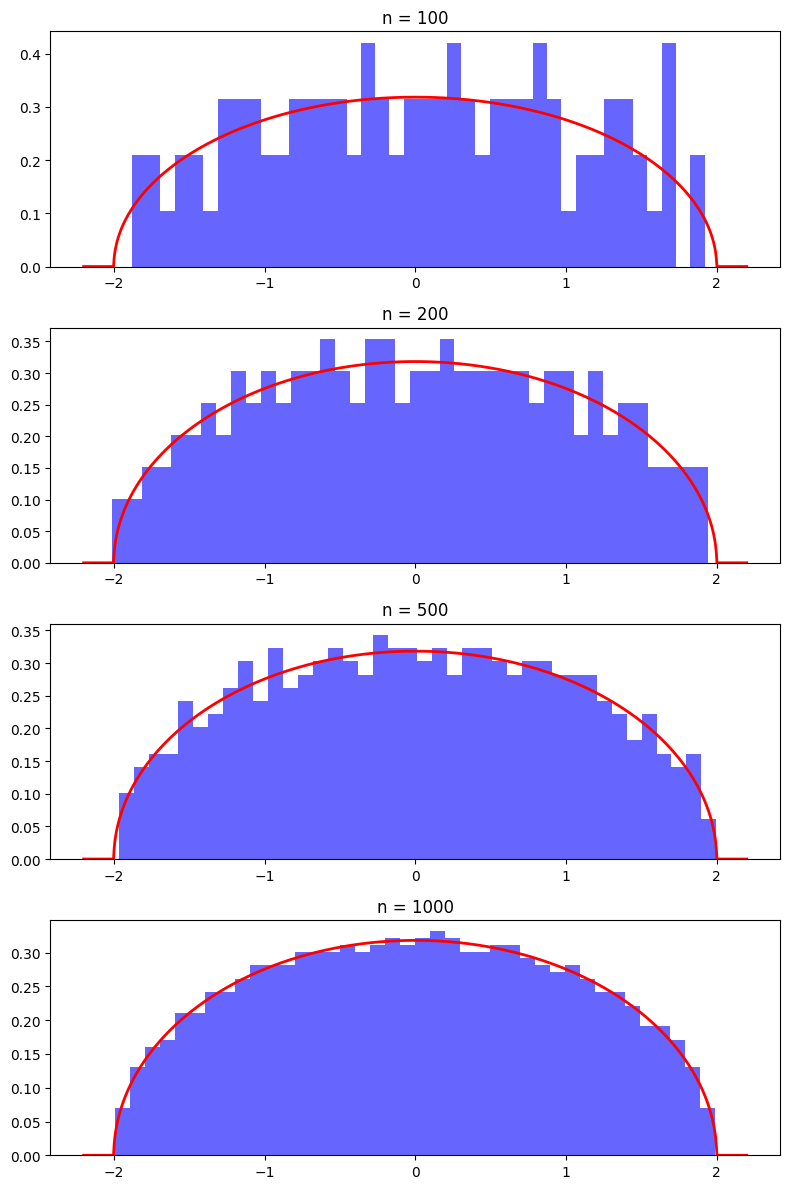

In [58]:
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(8,12))
x_curve = np.linspace(-2.2, 2.2, 1000)
y_curve = wigner_density(x_curve)

for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eigs = get_spectrum(Z)
    ax.hist(eigs, bins=40, density=True, color="blue", alpha=0.6)
    ax.plot(x_curve, y_curve, color="red", lw=2)
    ax.set_title(f"n = {n}")
plt.tight_layout()
plt.show()


# Conway 的生命游戏
## 1. is_valid_board(board) 判断棋盘是否合法：二维，元素只有0和1
> 验证：合法棋盘、一维数组、含2的数组，分别查看返回True/False


In [59]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all(np.isin(board, [0,1])):
        return False
    return True

# =====验证代码=====
board_ok = np.array([[1,0],[0,1]])
board_1d = np.array([1,0,1])
board_bad_val = np.array([[1,2],[0,0]])
print("合法棋盘is_valid:", is_valid_board(board_ok))
print("一维数组is_valid:", is_valid_board(board_1d))
print("含2的棋盘is_valid:", is_valid_board(board_bad_val))


合法棋盘is_valid: True
一维数组is_valid: False
含2的棋盘is_valid: False


## 2. gol_step(board)：执行生命游戏单步更新，环绕边界八邻居
> 验证：输入合法棋盘输出同样shape；非法棋盘抛出异常


In [60]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘格式无效")
    m,n = board.shape
    new_board = np.zeros_like(board)
    neighbors = np.zeros_like(board, dtype=int)
    for di in (-1,0,1):
        for dj in (-1,0,1):
            if di==0 and dj==0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    alive = board == 1
    dead = board ==0
    new_board[alive & ((neighbors==2)|(neighbors==3))] =1
    new_board[dead & (neighbors ==3)] =1
    return new_board

# =====验证代码=====
next_board = gol_step(board_ok)
print("原棋盘shape", board_ok.shape, "下一代shape", next_board.shape)
print("原棋盘:\n", board_ok)
print("下一代棋盘:\n", next_board)

try:
    gol_step(board_1d)
except ValueError as e:
    print("非法棋盘捕获异常：", e)


原棋盘shape (2, 2) 下一代shape (2, 2)
原棋盘:
 [[1 0]
 [0 1]]
下一代棋盘:
 [[0 0]
 [0 0]]
非法棋盘捕获异常： 棋盘格式无效


##3. draw_gol_board(board) 绘制棋盘，活细胞黑色，死细胞白色，隐藏坐标轴刻度网格
> 验证：调用绘图，图片弹出


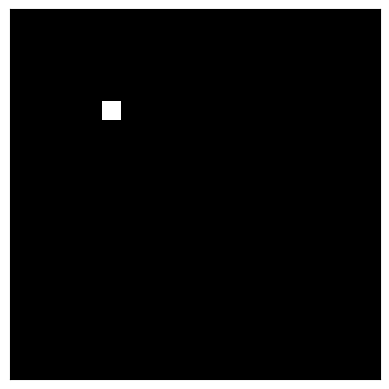

In [61]:
def draw_gol_board(board):
    plt.figure()
    plt.imshow(board, cmap="gray", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

# =====验证代码=====
test_board = np.zeros((20,20))
test_board[5,5] = 1
draw_gol_board(test_board)



# pandas 处理iris数据集任务
1.读取iris.csv，查看基本信息
2.修改索引34、37两行错误数据
3.新增 Petal.Ratio、Sepal.Ratio 两列
4.保存为 iris_corrected.csv
5.按花卉种类分组，计算均值、中位数、最小、最大、标准差


In [62]:
import pandas as pd

# 直接在线读取csv格式源文件，不是手写数据
csv_url = "https://raw.githubusercontent.com/uiuc-cse/data-fa14/gh-pages/data/iris.csv"
df = pd.read_csv(csv_url)

print("数据点数量：", len(df))
print("\n每列数据类型：")
print(df.dtypes)
print("\n列名：", df.columns.tolist())
print("\n花卉种类：", df["species"].unique())
print("花卉种类数量：", df["species"].nunique())

df.loc[34] = [4.9,3.1,1.5,0.2,"setosa"]
df.loc[37] = [4.9,3.6,1.4,0.1,"setosa"]
print("\n====修改后34行====")
print(df.loc[34])
print("\n====修改后37行====")
print(df.loc[37])

df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]
print("\n新增两列后前5行：")
print(df[["petal_length","petal_width","Petal.Ratio","sepal_length","sepal_width","Sepal.Ratio"]].head())

df.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv")

agg_result = df.groupby("species")[["Petal.Ratio","Sepal.Ratio"]].agg(["mean","median","min","max","std"])
print("\n====分组聚合结果====")
print(agg_result)


数据点数量： 150

每列数据类型：
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

列名： ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类： ['setosa' 'versicolor' 'virginica']
花卉种类数量： 3

====修改后34行====
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

====修改后37行====
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object

新增两列后前5行：
   petal_length  petal_width  Petal.Ratio  sepal_length  sepal_width  \
0           1.4          0.2          7.0           5.1          3.5   
1           1.4          0.2          7.0           4.9          3.0   
2           1.3          0.2          6.5           4.7          3.2   
3           1.5          0.2          7.5           4.6          3.1   
4           1.4          0.2     